In [1]:
########################################################
###################### Importierte Packete #############
########################################################

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.colors import rgb2hex

#import csv

import numpy as np
from numpy import diff

import pandas as pd

import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal
from scipy.interpolate import interp1d

import statsmodels.api as sm
from statsmodels.graphics.gofplots import qqplot

from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import itertools

import os

##### Saving/packing of data
import pickle

##### To create colour gradients
from colour import Color

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.battery.analysis import Extract_Charge_Discharge_Capacities
from scientific_utils.battery.analysis import Extract_Potential_Drop_Applied_Current
from scientific_utils.battery.analysis import Extract_Potential_Drop_During_OCV
from scientific_utils.general.plotting import Convert_cm_To_inch
from scientific_utils.general.plotting import Matplotlib_XvsY
from scientific_utils.general.plotting import Matplotlib_XvsY1Y2

In [3]:
# create the output folder if it does not exist yet
if not os.path.exists('./images/'):
    os.mkdir('./images/')

In [4]:
#########################################################
##################### Start of the code ##################
#########################################################

In [5]:
########## Open the .pkl file ########
########## Open the CP steps
##### CP charge steps
with open('../data/Batt15/processed/list_of_dataframes_of_CP_charge_equidistant_cycling.pkl', 'rb') as f:
    list_of_dataframes_of_CP_charge_equidistant_cycling = pickle.load(f)    

##### CP discharge steps
with open('../data/Batt15/processed/list_of_dataframes_of_CP_discharge_equidistant_cycling.pkl', 'rb') as f:
    list_of_dataframes_of_CP_discharge_equidistant_cycling = pickle.load(f)
    

########## Load the OCV steps after the CP step
##### OCVs after a Charging step in the Cycling process
with open('../data/Batt15/processed/list_of_dataframes_OCV_after_CP_step_charge_cycling.pkl', 'rb') as f:
    list_of_dataframes_OCV_after_CP_step_charge_cycling = pickle.load(f) 

##### OCVs after a Discharging step in the Cycling Process
with open('../data/Batt15/processed/list_of_dataframes_OCV_after_CP_step_discharge_cycling.pkl', 'rb') as f:
    list_of_dataframes_OCV_after_CP_step_discharge_cycling = pickle.load(f) 


In [6]:
#print(list_of_dataframes_of_CP_discharge_equidistant_cycling[0])
#print(list_of_dataframes_OCV_after_CP_step_discharge_cycling[0])

In [7]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 50 # number of colour points taken from the colour gradient with equal distance
colormap = plt.get_cmap('coolwarm', number_of_colorpoints) # Loads a ready-made colormap from Matplotlib
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list


In [8]:
########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    "pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    #"pgf.rcfonts": False,               # don't setup fonts from rc parameters
    "font.family": "sans-serif",           # standard sans-serif font of Matplotlib
    #"mathtext.fontset": "stixsans",
    "legend.title_fontsize" : 14,
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize" : Convert_cm_To_inch(16, 8),
    'savefig.dpi'         : 300,   ## figure dots per inch or 'figure'
    'savefig.facecolor'   : 'white',    ## figure facecolor when saving
    'savefig.edgecolor'   : 'white',    ## figure edgecolor when saving
    'savefig.format'      : 'png',      ## png, ps, pdf, svg
    'savefig.bbox'        : 'tight', 
    "pgf.preamble": "\n".join([
        r"\usepackage[T1]{fontenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage{fontspec}",        # plots will be generated using this preamble
        r"\usepackage{fourier}",
        r"\usepackage{unicode-math}",
        r"\usepackage[basic,italic,symbolgreek,numbers]{mathastext}"
        ])
    }

plt.rcParams.update(pgf_with_latex)

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)

In [9]:
############################### Defining Functions #################################

In [10]:
############################### Total Charging/Discharging Capacities #################################

In [11]:
list_of_dataframes_charging_steps = list_of_dataframes_of_CP_charge_equidistant_cycling
values_column_name_charge = 'Capacity (mAh)'
list_of_dataframes_discharging_steps = list_of_dataframes_of_CP_discharge_equidistant_cycling
values_column_name_discharge = 'Capacity (mAh)'

dataframes_of_charge_discharge_capacities_per_cycle = Extract_Charge_Discharge_Capacities(list_of_dataframes_charging_steps, values_column_name_charge, list_of_dataframes_discharging_steps, values_column_name_discharge)

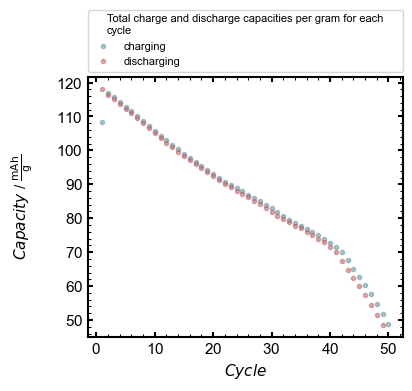

In [12]:
dataframe = dataframes_of_charge_discharge_capacities_per_cycle
x_values_column_name = 'Cycle'
y_values_column_name_first = 'Charge Capacity / mAh/g'
y_values_column_name_second = 'Discharge Capacity / mAh/g'
label_y_first = 'charging'
label_y_second = 'discharging'
y_ax_label = r'$ Capacity $ / $\frac{\mathsf{mAh}}{\mathsf{g}}$'
x_ax_label = r'$Cycle$'
save = 1
name_figure = 'Total_charge_and_discharge_capacities_per_gram_for_each_cycle' 
legend_title = 'Total charge and discharge capacities per gram for each cycle'

Matplotlib_XvsY1Y2(dataframe, x_values_column_name, y_values_column_name_first, y_values_column_name_second, label_y_first, label_y_second, y_ax_label, x_ax_label, save, name_figure, legend_title)

In [13]:
################################ Potential Drop CP to OCV #################################

In [14]:
list_of_dataframes_charging_cycles = list_of_dataframes_of_CP_charge_equidistant_cycling
column_names_charging = 'Voltage (V)'
list_of_dataframes_discharging_cycles = list_of_dataframes_of_CP_discharge_equidistant_cycling
column_names_discharging = 'Voltage (V)'
list_of_dataframes_OCV_after_charging = list_of_dataframes_OCV_after_CP_step_charge_cycling
column_names_ocv_charging = 'Voltage (V)'
list_of_dataframes_OCV_after_discharging = list_of_dataframes_OCV_after_CP_step_discharge_cycling
column_names_ocv_discharging = 'Voltage (V)'

dataframes_of_potential_drop_between_CP_and_OCV_per_cycle = Extract_Potential_Drop_Applied_Current(list_of_dataframes_charging_cycles, column_names_charging, list_of_dataframes_discharging_cycles, column_names_discharging, list_of_dataframes_OCV_after_charging, column_names_ocv_charging, list_of_dataframes_OCV_after_discharging, column_names_ocv_discharging)

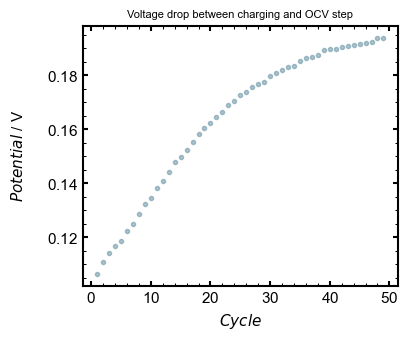

In [15]:
dataframe = dataframes_of_potential_drop_between_CP_and_OCV_per_cycle
x_values_column_name = 'Cycle'
y_values_column_name = 'DeltaV CP charge to OCV'
y_ax_label = r'$Potential$ / V'
x_ax_label = r'$Cycle$'
label_graph = 'charge'
save = 1 
name_figure = 'Voltage_drop_between_charging_and_OCV_step'
legend_title = 'Voltage drop between charging and OCV step'

Matplotlib_XvsY(dataframe, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, label_graph, save, name_figure,legend_title)

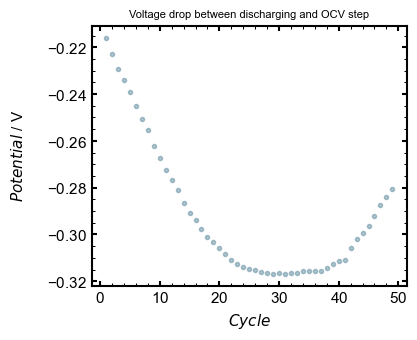

In [16]:
dataframe = dataframes_of_potential_drop_between_CP_and_OCV_per_cycle
x_values_column_name = 'Cycle'
y_values_column_name = 'DeltaV CP discharge to OCV'
y_ax_label = r'$Potential$ / V'
x_ax_label = r'$Cycle$'
label_graph = 'discharge'
save = 1 
name_figure = 'Voltage_drop_between_discharging_and_OCV_step'
legend_title = 'Voltage drop between discharging and OCV step'

Matplotlib_XvsY(dataframe, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, label_graph, save, name_figure,legend_title)

In [17]:
############################# Potential difference between Start of OCV and End of OCV ############################

In [18]:
list_of_dataframes_OCV_after_charge = list_of_dataframes_OCV_after_CP_step_charge_cycling
list_of_dataframes_OCV_after_discharge = list_of_dataframes_OCV_after_CP_step_discharge_cycling

dataframes_of_potential_drop_beginning_OCV_and_end_OCV_per_cycle = Extract_Potential_Drop_During_OCV(list_of_dataframes_OCV_after_charge, 'Voltage (V)', list_of_dataframes_OCV_after_discharge, 'Voltage (V)')

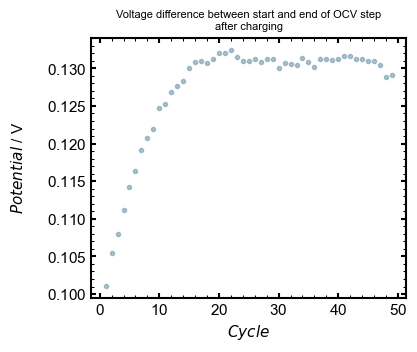

In [19]:
dataframe = dataframes_of_potential_drop_beginning_OCV_and_end_OCV_per_cycle
x_values_column_name = 'Cycle'
y_values_column_name = 'Potential Difference OCV charge at end'
y_ax_label = r'$Potential$ / V'
x_ax_label = r'$Cycle$'
label_graph = 'charge'
save = 1 
name_figure = 'Voltage_difference_between_start_and_end_of_OCV_step_after_charging'
legend_title = 'Voltage difference between start and end of OCV step after charging'

Matplotlib_XvsY(dataframe, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, label_graph, save, name_figure,legend_title)

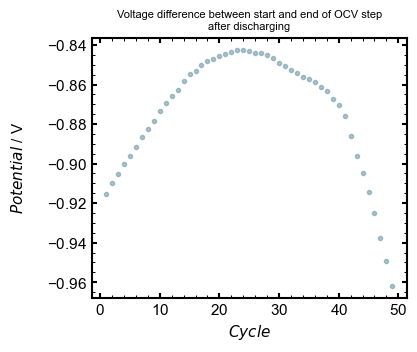

In [20]:
dataframe = dataframes_of_potential_drop_beginning_OCV_and_end_OCV_per_cycle
x_values_column_name = 'Cycle'
y_values_column_name = 'Potential Difference OCV discharge at end'
y_ax_label = r'$Potential$ / V'
x_ax_label = r'$Cycle$'
label_graph = 'discharge'
save = 1 
name_figure = 'Voltage_difference_between_start_and_end_of_OCV_step_after_discharging'
legend_title = 'Voltage difference between start and end of OCV step after discharging'

Matplotlib_XvsY(dataframe, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, label_graph, save, name_figure,legend_title)

In [21]:
########################## Saving of the generated Dataframes ####################

In [22]:
########## Save the data as .pkl ##########
with open('../data/Batt15/processed/dataframes_of_charge_discharge_capacities_per_cycle.pkl', 'wb') as f:
    pickle.dump(dataframes_of_charge_discharge_capacities_per_cycle, f)

with open('../data/Batt15/processed/dataframes_of_potential_drop_between_CP_and_OCV_per_cycle.pkl', 'wb') as f:
    pickle.dump(dataframes_of_potential_drop_between_CP_and_OCV_per_cycle, f) 
    
with open('../data/Batt15/processed/dataframes_of_potential_drop_beginning_OCV_and_end_OCV_per_cycle.pkl', 'wb') as f:
    pickle.dump(dataframes_of_potential_drop_beginning_OCV_and_end_OCV_per_cycle, f) 